In [2]:
import importlib
import nystrom_functions
importlib.reload(nystrom_functions)

import numpy as np
import matplotlib.pyplot as plt
import time
import pandas as pd

from sklearn.preprocessing import StandardScaler
from KRR_utils import *
from nystrom_functions import *

In [3]:
# data setup and full KRR baseline

rng = np.random.default_rng(1)

df = pd.read_csv("../Data/train.csv")
X = df.iloc[:, :-1].to_numpy(dtype=float)
y = df.iloc[:, -1].to_numpy(dtype=float)

# sample sizes for training and testing
n_train = 19000
n_test = 1000

# this is the KRR lambda in (K + lambda I) * alpha = y
krr_lam = 1e-2

# sampled columns for uniform and approximate leverage
l_values = [50, 100, 200, 400, 800, 1600]

# this is the recursive parameter, not the same lamda for some reason
rec_lam_values = [1000, 2000, 5000, 10000, 20000]
rec_delta = 0.1
rec_base_size = None # for testing

# approximate leverage starts with these many uniform columns
ini_l_fixed = 100

# this is a check that compares the factorized solver to an explicit solve of (K_tilde + lambda I) only used to verify the solver works
check_explicit_solve = False

ind = rng.choice(X.shape[0], size=n_train + n_test, replace=False)

train_ind = ind[:n_train]
test_ind = ind[n_train:]
X_train_raw = X[train_ind]
y_train = y[train_ind]
X_test_raw = X[test_ind]
y_test = y[test_ind]
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

gamma = 1 / X_train.shape[1]

def rbf_final(A, B):
    K = rbf(A, B, gamma=gamma)
    return K

def get_mse(y_true, y_pred):
    err = np.mean((y_true - y_pred)**2)
    return err

print("n_train =", n_train)
print("n_test =", n_test)
print("krr lambda =", krr_lam)
print("gamma =", gamma)

# full kernel direct form and solve
start_time = time.perf_counter()
K_train = rbf_final(X_train, X_train)
K_test = rbf_final(X_test, X_train)
full_kernel_time = time.perf_counter() - start_time

start_time = time.perf_counter()
alpha_full = np.linalg.solve(K_train + krr_lam*np.eye(n_train), y_train)
y_hat_full = K_test @ alpha_full
full_solve_time = time.perf_counter() - start_time

full_total_time = full_kernel_time + full_solve_time
full_mse = get_mse(y_test, y_hat_full)

K_norm = np.linalg.norm(K_train, ord="fro")
y_norm = np.linalg.norm(y_train)
alpha_norm = np.linalg.norm(alpha_full)

print("full KRR mse =", full_mse)
print("full kernel time =", full_kernel_time)
print("full solve time =", full_solve_time)
print("full total time =", full_total_time)

n_train = 19000
n_test = 1000
krr lambda = 0.01
gamma = 0.012345679012345678
full KRR mse = 116.53541200161642
full kernel time = 21.950453100027516
full solve time = 38.19843630003743
full total time = 60.148889400064945


In [33]:
# uniform and approximate leverage experiments

rows = []

for l in l_values:
    print("")
    print("l =", l)

    # uniform sampling
    
    print("uniform")

    start_time = time.perf_counter()
    uni_ind = uniform_sampling(n_train, l, rng)
    sample_time = time.perf_counter() - start_time

    start_time = time.perf_counter()
    alpha_uni, y_hat_uni, U_uni, eig_uni, C_uni, W_uni = solver(
        X_train,
        rbf_final,
        uni_ind,
        y_train,
        krr_lam,
        X_test=X_test,
        return_factors=True
    )
    solve_time = time.perf_counter() - start_time

    K_uni = (U_uni * eig_uni) @ U_uni.T

    uni_kernel_err = np.linalg.norm(K_train - K_uni, ord="fro") / K_norm
    uni_alpha_err = np.linalg.norm(alpha_full - alpha_uni) / alpha_norm
    uni_res = np.linalg.norm((K_train @ alpha_uni + krr_lam*alpha_uni) - y_train) / y_norm
    uni_nys_res = np.linalg.norm((K_uni @ alpha_uni + krr_lam*alpha_uni) - y_train) / y_norm
    uni_mse = get_mse(y_test, y_hat_uni)

    if check_explicit_solve:
        alpha_uni_explicit = np.linalg.solve(K_uni + krr_lam*np.eye(n_train), y_train)
        uni_solver_err = np.linalg.norm(alpha_uni - alpha_uni_explicit) / np.linalg.norm(alpha_uni_explicit)
    else:
        uni_solver_err = np.nan

    rows.append([
        l,
        "uniform",
        np.nan, #empty column for rls
        uni_kernel_err,
        uni_alpha_err,
        uni_res,
        uni_nys_res,
        uni_solver_err,
        uni_mse,
        sample_time,
        solve_time,
        sample_time + solve_time
    ])

    print("kernel error =", uni_kernel_err)
    print("alpha error =", uni_alpha_err)
    print("System residual =", uni_res)
    print("Nystrom residual =", uni_nys_res)
    print("test mse =", uni_mse)
    print("sample_time =", sample_time)
    print("solve_time =", solve_time)
    print("time =", sample_time + solve_time)


    # approximate leverage sampling
    
    print("approx leverage")

    ini_l = min(ini_l_fixed, max(1, l // 2))
    extra_l = l - ini_l

    start_time = time.perf_counter()
    app_ind, app_scores, ini_ind = approximate_leverage_kernel(
        X_train,
        rbf_final,
        ini_l,
        extra_l,
        rng
    )
    sample_time = time.perf_counter() - start_time

    start_time = time.perf_counter()
    alpha_app, y_hat_app, U_app, eig_app, C_app, W_app = solver(
        X_train,
        rbf_final,
        app_ind,
        y_train,
        krr_lam,
        X_test=X_test,
        return_factors=True
    )
    solve_time = time.perf_counter() - start_time

    K_app = (U_app * eig_app) @ U_app.T

    app_kernel_err = np.linalg.norm(K_train - K_app, ord="fro") / K_norm
    app_alpha_err = np.linalg.norm(alpha_full - alpha_app) / alpha_norm
    app_res = np.linalg.norm((K_train @ alpha_app + krr_lam*alpha_app) - y_train) / y_norm
    app_nys_res = np.linalg.norm((K_app @ alpha_app + krr_lam*alpha_app) - y_train) / y_norm
    app_mse = get_mse(y_test, y_hat_app)

    if check_explicit_solve:
        alpha_app_explicit = np.linalg.solve(K_app + krr_lam*np.eye(n_train), y_train)
        app_solver_err = np.linalg.norm(alpha_app - alpha_app_explicit) / np.linalg.norm(alpha_app_explicit)
    else:
        app_solver_err = np.nan

    rows.append([
        len(app_ind),
        "approx leverage",
        np.nan,
        app_kernel_err,
        app_alpha_err,
        app_res,
        app_nys_res,
        app_solver_err,
        app_mse,
        sample_time,
        solve_time,
        sample_time + solve_time
    ])

    print("kernel error =", app_kernel_err)
    print("alpha error =", app_alpha_err)
    print("System residual =", app_res)
    print("Nystrom residual =", app_nys_res)
    print("test mse =", app_mse)
    print("sample_time =", sample_time)
    print("solve_time =", solve_time)
    print("time =", sample_time + solve_time)


l = 50
uniform
kernel error = 0.08649732008417906
alpha error = 1.0689225648777676
System residual = 815.3408450675348
Nystrom residual = 4.286411549123523e-10
test mse = 244.69825203581036
sample_time = 0.0031220000237226486
solve_time = 0.12770630000159144
time = 0.1308283000253141
approx leverage
kernel error = 0.08179837252535119
alpha error = 1.1794252438300699
System residual = 666.2620034483665
Nystrom residual = 5.585049827209997e-10
test mse = 280.9249441333145
sample_time = 0.139849100029096
solve_time = 0.09751809993758798
time = 0.23736719996668398

l = 100
uniform
kernel error = 0.04768240229220381
alpha error = 0.971448565155479
System residual = 384.7781359033265
Nystrom residual = 2.357192715201881e-10
test mse = 230.1725111918898
sample_time = 0.0007658000104129314
solve_time = 0.3003503999207169
time = 0.3011161999311298
approx leverage
kernel error = 0.058913402790309176
alpha error = 1.014671513116756
System residual = 486.6240632032669
Nystrom residual = 7.1729551

In [34]:
# recursive RLS
k_diag_train = np.diag(K_train).copy()

for rec_lam in rec_lam_values:
    print("")
    print("recursive RLS, rec_lam =", rec_lam)

    start_time = time.perf_counter()
    rec_ind, rec_weight = recursive_nystrom(
        X_train,
        rbf_final,
        rec_lam,
        rec_delta,
        rng,
        k_diag_train,
        rec_base_size
    )
    sample_time = time.perf_counter() - start_time

    start_time = time.perf_counter()
    alpha_rec, y_hat_rec, U_rec, eig_rec, C_rec, W_rec = solver(
        X_train,
        rbf_final,
        rec_ind,
        y_train,
        krr_lam,
        X_test=X_test,
        return_factors=True
    )
    solve_time = time.perf_counter() - start_time

    K_rec = (U_rec * eig_rec) @ U_rec.T

    rec_kernel_err = np.linalg.norm(K_train - K_rec, ord="fro") / K_norm
    rec_alpha_err = np.linalg.norm(alpha_full - alpha_rec) / alpha_norm
    rec_res = np.linalg.norm((K_train @ alpha_rec + krr_lam*alpha_rec) - y_train) / y_norm
    rec_nys_res = np.linalg.norm((K_rec @ alpha_rec + krr_lam*alpha_rec) - y_train) / y_norm
    rec_mse = get_mse(y_test, y_hat_rec)

    if check_explicit_solve:
        alpha_rec_explicit = np.linalg.solve(K_rec + krr_lam*np.eye(n_train), y_train)
        rec_solver_err = np.linalg.norm(alpha_rec - alpha_rec_explicit) / np.linalg.norm(alpha_rec_explicit)
    else:
        rec_solver_err = np.nan

    rows.append([
        len(rec_ind),
        "recursive RLS",
        rec_lam,
        rec_kernel_err,
        rec_alpha_err,
        rec_res,
        rec_nys_res,
        rec_solver_err,
        rec_mse,
        sample_time,
        solve_time,
        sample_time + solve_time
    ])

    print("selected columns =", len(rec_ind))
    print("kernel error =", rec_kernel_err)
    print("alpha error =", rec_alpha_err)
    print("System residual =", rec_res)
    print("Nystrom residual =", rec_nys_res)
    print("test mse =", rec_mse)
    print("time =", sample_time + solve_time)


recursive RLS, rec_lam = 1000
selected columns = 1453
kernel error = 0.004270516191329782
alpha error = 0.3777585454798034
System residual = 5.2613791114882
Nystrom residual = 3.711472432692747e-10
test mse = 132.46305346558142
time = 111.13704619999044

recursive RLS, rec_lam = 2000
selected columns = 714
kernel error = 0.008872085570843645
alpha error = 0.5231401545628166
System residual = 11.718180057545757
Nystrom residual = 1.3094339528370697e-10
test mse = 156.18957725145884
time = 81.06666540005244

recursive RLS, rec_lam = 5000
selected columns = 287
kernel error = 0.02141944390718266
alpha error = 0.7166185678442247
System residual = 127.13827479348355
Nystrom residual = 1.1290162210761936e-09
test mse = 178.29433673217883
time = 19.284213700098917

recursive RLS, rec_lam = 10000
selected columns = 141
kernel error = 0.04504583724737411
alpha error = 0.8697756090104601
System residual = 151.92333657819
Nystrom residual = 1.4513427610532106e-09
test mse = 205.38105890218708
ti

In [35]:
# table

columns = [
    "l",
    "method",
    "rec_lam",
    "relative_kernel_error",
    "relative_alpha_error",
    "system_residual",
    "nystrom_system_residual",
    "explicit_solver_error",
    "test_mse",
    "sample_time",
    "solve_time",
    "total_time"
]

results = pd.DataFrame(rows, columns=columns)
# results.to_csv("../Results/final_experiments/table_of_final_results.csv", index=False)
results

,l,method,rec_lam,relative_kernel_error,relative_alpha_error,system_residual,nystrom_system_residual,explicit_solver_error,test_mse,sample_time,solve_time,total_time
0,50,uniform,NaN,0.086497,1.068923,815.340845,4.286412e-10,NaN,244.698252,0.003122,0.127706,0.130828
1,50,approx leverage,NaN,0.081798,1.179425,666.262003,5.585050e-10,NaN,280.924944,0.139849,0.097518,0.237367
2,100,uniform,NaN,0.047682,0.971449,384.778136,2.357193e-10,NaN,230.172511,0.000766,0.300350,0.301116
3,100,approx leverage,NaN,0.058913,1.014672,486.624063,7.172955e-10,NaN,243.822377,0.172322,0.254183,0.426505
4,200,uniform,NaN,0.031674,0.780666,142.958434,6.030414e-10,NaN,188.594747,0.000068,4.895976,4.896044
5,200,approx leverage,NaN,0.034772,0.846197,191.561866,4.505845e-10,NaN,195.744190,0.238618,5.969381,6.208000
6,400,uniform,NaN,0.017292,0.633416,39.020641,1.347920e-10,NaN,163.770825,0.001276,25.770398,25.771675
7,400,approx leverage,NaN,0.023216,0.620593,59.456934,5.964196e-10,NaN,160.530470,0.322540,31.351051,31.673591
8,800,uniform,NaN,0.010815,0.464774,12.244351,9.089339e-10,NaN,144.882038,0.000131,73.198205,73.198336
9,800,approx leverage,NaN,0.014120,0.491391,74.213461,2.163801e-10,NaN,147.355361,0.298550,74.743678,75.042228


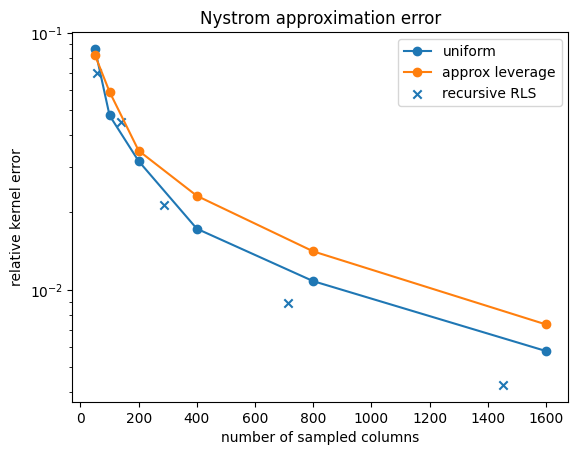

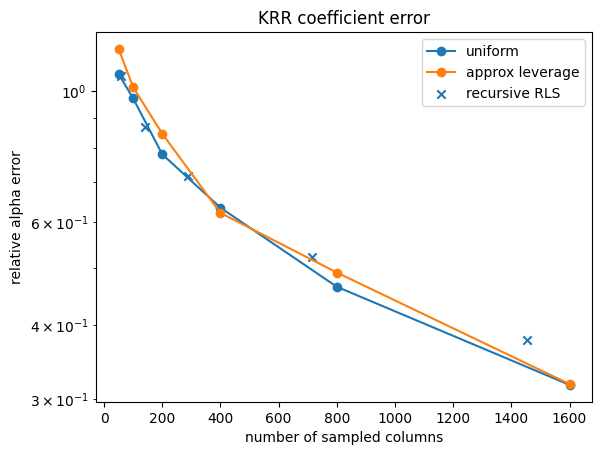

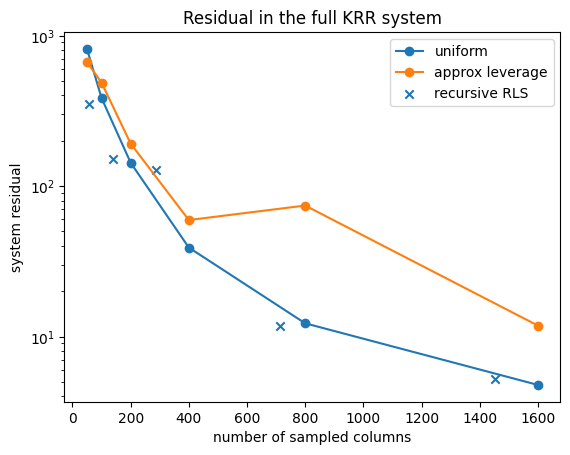

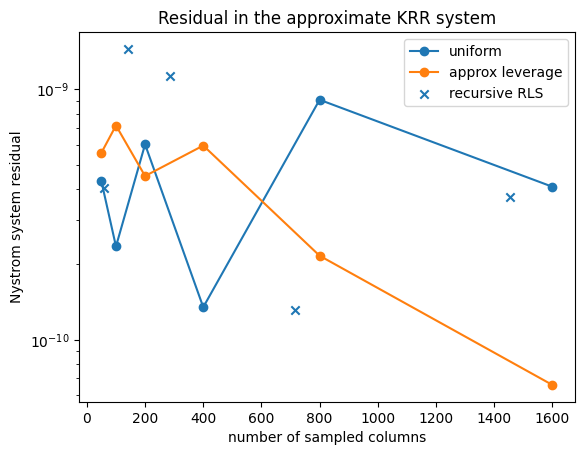

In [ ]:
# main plots

plot_df = results.copy()

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l")
    plt.semilogy(sub["l"], sub["relative_kernel_error"], marker="o", label=method, color="blue" if method == "uniform" else "orange")
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.scatter(sub["l"], sub["relative_kernel_error"], marker="x", label="recursive RLS", color="green")
plt.xlabel("number of sampled columns")
plt.ylabel("relative kernel error")
plt.title("Nystrom approximation error")
plt.legend()
#plt.savefig("../Results/final_kernel_error_vs_l.pdf") 
plt.show()

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l")
    plt.semilogy(sub["l"], sub["relative_alpha_error"], marker="o", label=method, color="blue" if method == "uniform" else "orange")
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.scatter(sub["l"], sub["relative_alpha_error"], marker="x", label="recursive RLS", color="green")
plt.xlabel("number of sampled columns")
plt.ylabel("relative alpha error")
plt.title("KRR coefficient error")
plt.legend()
##plt.savefig("../Results/final_alpha_error_vs_l.pdf") 
plt.show()

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l")
    plt.semilogy(sub["l"], sub["system_residual"], marker="o", label=method, color="blue" if method == "uniform" else "orange")
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.scatter(sub["l"], sub["system_residual"], marker="x", label="recursive RLS", color="green")
plt.xlabel("number of sampled columns")
plt.ylabel("system residual")
plt.title("Residual in the full KRR system")
plt.legend()
#plt.savefig("../Results/final_full_system_residual_vs_l.pdf") 
plt.show()

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l")
    plt.semilogy(sub["l"], sub["nystrom_system_residual"], marker="o", label=method, color="blue" if method == "uniform" else "orange")
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.scatter(sub["l"], sub["nystrom_system_residual"], marker="x", label="recursive RLS", color="green")
plt.xlabel("number of sampled columns")
plt.ylabel("Nystrom system residual")
plt.title("Residual in the approximate KRR system")
plt.legend()
#plt.savefig("../Results/final_nystrom_system_residual_vs_l.pdf") 
plt.show()

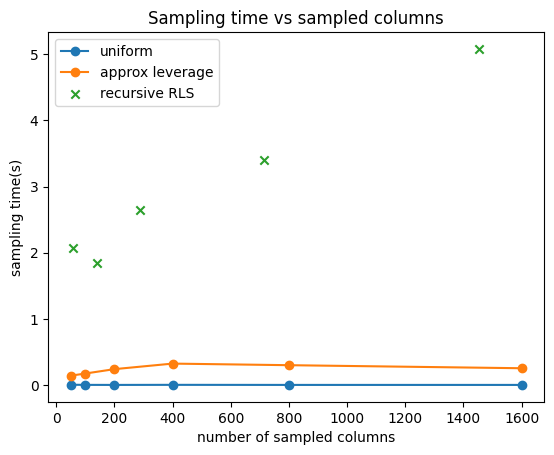

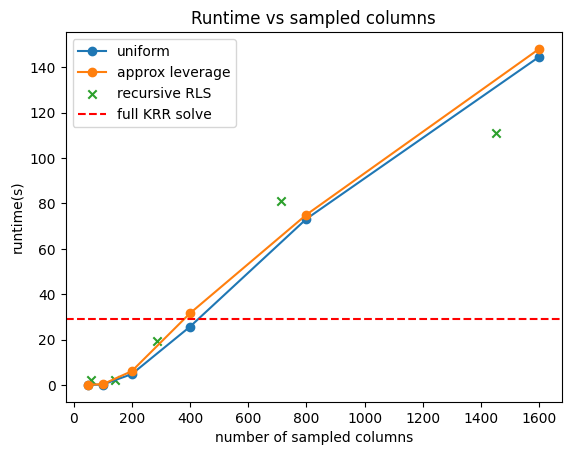

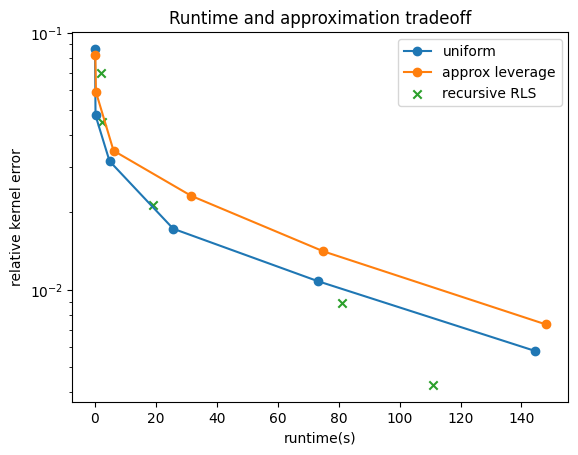

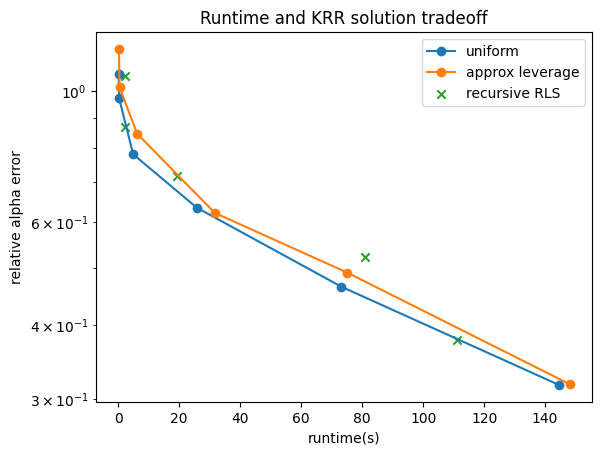

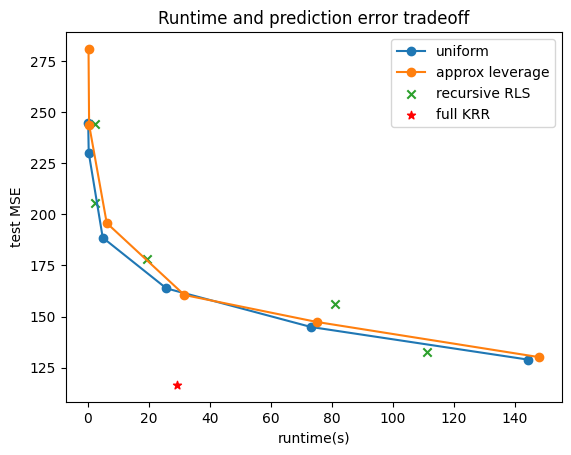

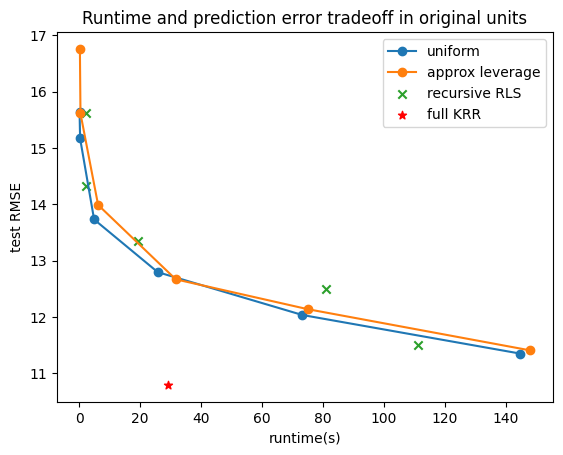

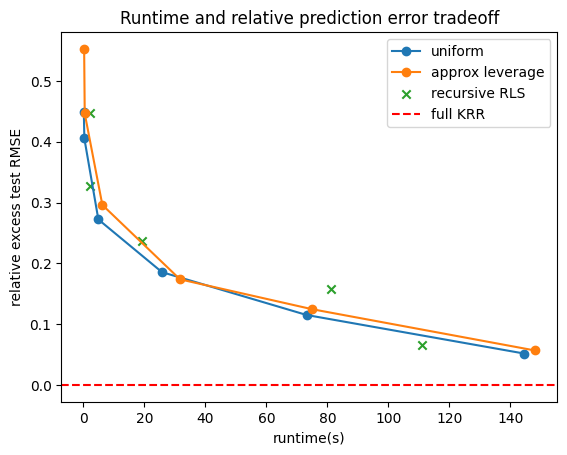

In [ ]:
# runtime plots

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l")
    plt.plot(sub["l"], sub["sample_time"], marker="o", label=method, color="blue" if method == "uniform" else "orange")
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.scatter(sub["l"], sub["sample_time"], marker="x", label="recursive RLS", color="green")
plt.xlabel("number of sampled columns")
plt.ylabel("sampling time(s)")
plt.title("Sampling time vs sampled columns")
plt.legend()
#plt.savefig("../Results/final_sample_time_vs_l.pdf") 
plt.show()

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l")
    plt.plot(sub["l"], sub["total_time"], marker="o", label=method, color="blue" if method == "uniform" else "orange")
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.scatter(sub["l"], sub["total_time"], marker="x", label="recursive RLS", color="green")
plt.axhline(full_solve_time, linestyle="--", label="full KRR solve", color="red")
plt.xlabel("number of sampled columns")
plt.ylabel("runtime(s)")
plt.title("Runtime vs sampled columns")
plt.legend()
#plt.savefig("../Results/final_total_time_vs_l.pdf") 
plt.show()

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("total_time")
    plt.semilogy(sub["total_time"], sub["relative_kernel_error"], marker="o", label=method, color="blue" if method == "uniform" else "orange")
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.scatter(sub["total_time"], sub["relative_kernel_error"], marker="x", label="recursive RLS", color="green")
plt.xlabel("runtime(s)")
plt.ylabel("relative kernel error")
plt.title("Runtime and approximation tradeoff")
plt.legend()
#plt.savefig("../Results/final_runtime_kernel_error_tradeoff.pdf") 
plt.show()

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("total_time")
    plt.semilogy(sub["total_time"], sub["relative_alpha_error"], marker="o", label=method, color="blue" if method == "uniform" else "orange")
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.scatter(sub["total_time"], sub["relative_alpha_error"], marker="x", label="recursive RLS", color="green")
plt.xlabel("runtime(s)")
plt.ylabel("relative alpha error")
plt.title("Runtime and KRR solution tradeoff")
plt.legend()
#plt.savefig("../Results/final_runtime_alpha_error_tradeoff.pdf") 
plt.show()

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("total_time")
    plt.plot(sub["total_time"], sub["test_mse"], marker="o", label=method, color="blue" if method == "uniform" else "orange")
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.scatter(sub["total_time"], sub["test_mse"], marker="x", label="recursive RLS", color="green")
plt.scatter([full_solve_time], [full_mse], marker="*", label="full KRR", color="red")
plt.xlabel("runtime(s)")
plt.ylabel("test MSE")
plt.title("Runtime and prediction error tradeoff")
plt.legend()
#plt.savefig("../Results/final_runtime_test_mse_tradeoff.pdf") #s
plt.show()

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("total_time")
    plt.plot(sub["total_time"], np.sqrt(sub["test_mse"]), marker="o", label=method, color="blue" if method == "uniform" else "orange")
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.scatter(sub["total_time"], np.sqrt(sub["test_mse"]), marker="x", label="recursive RLS", color="green")
plt.scatter([full_solve_time], [np.sqrt(full_mse)], marker="*", label="full KRR", color="red")
plt.xlabel("runtime(s)")
plt.ylabel("test RMSE")
plt.title("Runtime and prediction error tradeoff in original units")
plt.legend()
#plt.savefig("../Results/final_runtime_test_rmse_tradeoff.pdf") #s
plt.show()

plot_df["relative_excess_rmse"] = (np.sqrt(plot_df["test_mse"]) - np.sqrt(full_mse)) / np.sqrt(full_mse)

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("total_time")
    plt.plot(sub["total_time"], sub["relative_excess_rmse"], marker="o", label=method, color="blue" if method == "uniform" else "orange")
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.scatter(sub["total_time"], sub["relative_excess_rmse"], marker="x", label="recursive RLS", color="green")
plt.axhline(0, linestyle="--", label="full KRR", color="red")
plt.xlabel("runtime(s)")
plt.ylabel("relative excess test RMSE")
plt.title("Runtime and relative prediction error tradeoff")
plt.legend()
#plt.savefig("../Results/final_runtime_relative_excess_rmse_tradeoff.pdf") #s
plt.show()

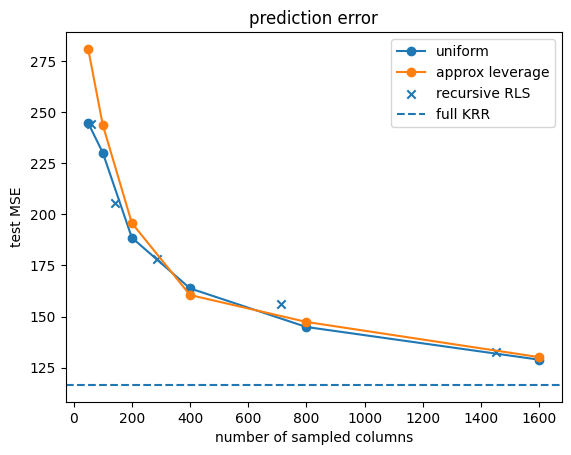

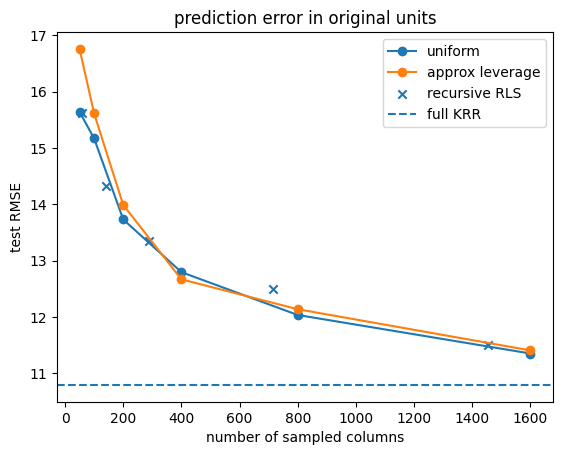

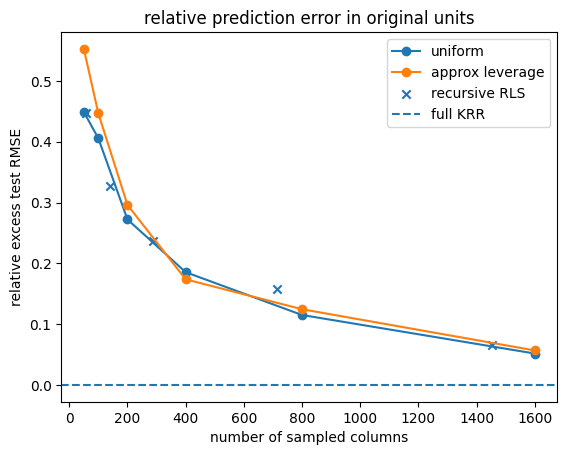

In [ ]:
# prediction error check

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l")
    plt.plot(sub["l"], sub["test_mse"], marker="o", label=method, color="blue" if method == "uniform" else "orange")
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.scatter(sub["l"], sub["test_mse"], marker="x", label="recursive RLS", color="green")
plt.axhline(full_mse, linestyle="--", label="full KRR", color="red")
plt.xlabel("number of sampled columns")
plt.ylabel("test MSE")
plt.title("prediction error")
plt.legend()
#plt.savefig("../Results/final_test_mse_vs_l.pdf") 
plt.show()

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l")
    plt.plot(sub["l"], np.sqrt(sub["test_mse"]), marker="o", label=method, color="blue" if method == "uniform" else "orange") #square root of mse
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.scatter(sub["l"], np.sqrt(sub["test_mse"]), marker="x", label="recursive RLS", color="green")
plt.axhline(np.sqrt(full_mse), linestyle="--", label="full KRR", color="red")
plt.xlabel("number of sampled columns")
plt.ylabel("test RMSE")
plt.title("prediction error in original units")
plt.legend()
#plt.savefig("../Results/final_test_rmse_vs_l.pdf") 
plt.show()

plot_df["relative_excess_rmse"] = (np.sqrt(plot_df["test_mse"]) - np.sqrt(full_mse)) / np.sqrt(full_mse) 

plt.figure()
for method in ["uniform", "approx leverage"]:
    sub = plot_df[plot_df["method"] == method].sort_values("l")
    plt.plot(sub["l"], sub["relative_excess_rmse"], marker="o", label=method, color="blue" if method == "uniform" else "orange")
sub = plot_df[plot_df["method"] == "recursive RLS"]
plt.scatter(sub["l"], sub["relative_excess_rmse"], marker="x", label="recursive RLS", color="green")
plt.axhline(0, linestyle="--", label="full KRR", color="red")
plt.xlabel("number of sampled columns")
plt.ylabel("relative excess test RMSE")
plt.title("relative prediction error in original units")
plt.legend()
#plt.savefig("../Results/final_relative_excess_rmse_vs_l.pdf")
plt.show()

In [4]:
# experimental recursive RLS lambda

rec_lam_values = [1000, 2000, 5000, 10000]
rec_rows = []
k_diag_train = np.diag(K_train).copy()

for rec_lam in rec_lam_values:
    print("")
    print("rec_lam =", rec_lam)

    start_time = time.perf_counter()
    rec_ind, rec_weight = recursive_nystrom(
        X_train,
        rbf_final,
        rec_lam,
        rec_delta,
        rng,
        k_diag_train,
        rec_base_size
    )
    sample_time = time.perf_counter() - start_time

    print("selected columns =", len(rec_ind))
    print("sampling time =", sample_time)

    start_time = time.perf_counter()
    alpha_rec, y_hat_rec, U_rec, eig_rec, C_rec, W_rec = solver(
        X_train,
        rbf_final,
        rec_ind,
        y_train,
        krr_lam,
        X_test=X_test,
        return_factors=True
    )
    solve_time = time.perf_counter() - start_time

    K_rec = (U_rec * eig_rec) @ U_rec.T

    rec_kernel_err = np.linalg.norm(K_train - K_rec, ord="fro") / K_norm
    rec_alpha_err = np.linalg.norm(alpha_full - alpha_rec) / alpha_norm
    rec_res = np.linalg.norm((K_train @ alpha_rec + krr_lam * alpha_rec) - y_train) / y_norm
    rec_nys_res = np.linalg.norm((K_rec @ alpha_rec + krr_lam * alpha_rec) - y_train) / y_norm
    rec_mse = get_mse(y_test, y_hat_rec)

    print("kernel error =", rec_kernel_err)
    print("alpha error =", rec_alpha_err)
    print("System residual =", rec_res)
    print("Nystrom residual =", rec_nys_res)
    print("test mse =", rec_mse)
    print("solve time =", solve_time)

    rec_rows.append([
        rec_lam,
        len(rec_ind),
        sample_time,
        solve_time,
        sample_time + solve_time,
        rec_kernel_err,
        rec_alpha_err,
        rec_res,
        rec_nys_res,
        rec_mse
    ])

rec_exp_df = pd.DataFrame(
    rec_rows,
    columns=[
        "rec_lam",
        "l",
        "sample_time",
        "solve_time",
        "total_time",
        "kernel_error",
        "alpha_error",
        "full_system_residual",
        "nystrom_system_residual",
        "test_mse"
    ]
)

rec_exp_df


rec_lam = 1000
selected columns = 1428
sampling time = 5.218147299950942
kernel error = 0.004036742105784515
alpha error = 0.3694293377106352
System residual = 6.037136361402126
Nystrom residual = 2.900160522162396e-10
test mse = 137.01401822032452
solve time = 97.51930029992945

rec_lam = 2000
selected columns = 727
sampling time = 1.0078052999451756
kernel error = 0.008696303098924744
alpha error = 0.5048449519633583
System residual = 11.872475137139787
Nystrom residual = 5.484136601501343e-10
test mse = 147.95013304486994
solve time = 12.238942500203848

rec_lam = 5000
selected columns = 327
sampling time = 0.8302875000517815
kernel error = 0.020022422327947854
alpha error = 0.6858095200151807
System residual = 55.92978517705946
Nystrom residual = 6.388335923955783e-10
test mse = 175.24297656621317
solve time = 3.9545138000976294

rec_lam = 10000
selected columns = 141
sampling time = 0.7521099001169205
kernel error = 0.0396938196696816
alpha error = 0.836588183166678
System residu

,rec_lam,l,sample_time,solve_time,total_time,kernel_error,alpha_error,full_system_residual,nystrom_system_residual,test_mse
0,1000,1428,5.218147,97.519300,102.737448,0.004037,0.369429,6.037136,2.900161e-10,137.014018
1,2000,727,1.007805,12.238943,13.246748,0.008696,0.504845,11.872475,5.484137e-10,147.950133
2,5000,327,0.830288,3.954514,4.784801,0.020022,0.685810,55.929785,6.388336e-10,175.242977
3,10000,141,0.752110,0.366247,1.118357,0.039694,0.836588,211.082243,3.785607e-10,205.753471


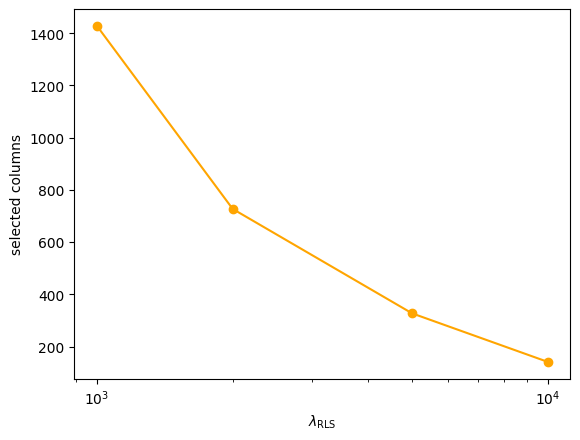

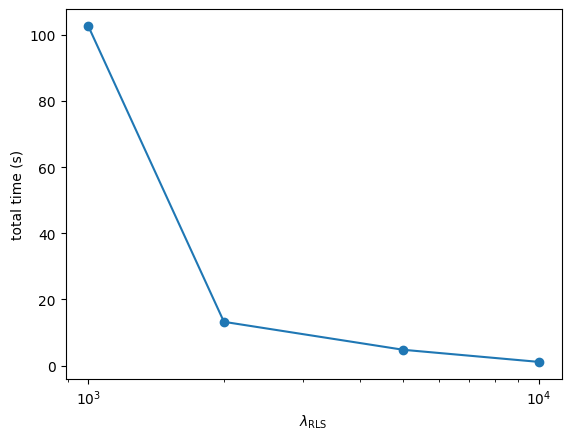

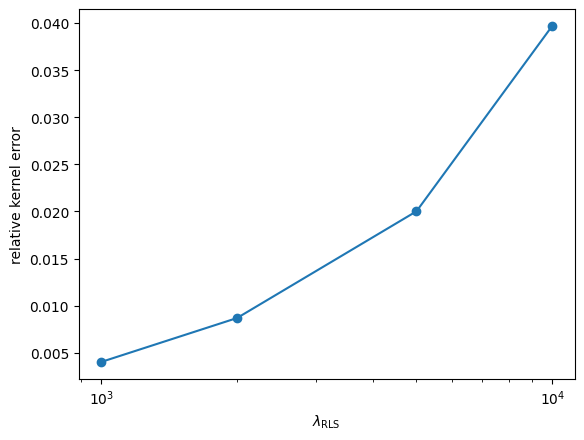

In [9]:
plt.figure()
plt.semilogx(rec_exp_df["rec_lam"], rec_exp_df["l"], marker="o")
plt.xlabel("$\lambda_{\mathrm{RLS}}$")
plt.ylabel("selected columns")
#plt.savefig("../Results/final_recursive_lambda_selected_columns.pdf") 
plt.show()

plt.figure()
plt.semilogx(rec_exp_df["rec_lam"], rec_exp_df["total_time"], marker="o")
plt.xlabel("$\lambda_{\mathrm{RLS}}$")
plt.ylabel("total time (s)")
#plt.savefig("../Results/final_recursive_lambda_total_time.pdf") 
plt.show()

plt.figure()
plt.semilogx(rec_exp_df["rec_lam"], rec_exp_df["kernel_error"], marker="o")
plt.xlabel("$\lambda_{\mathrm{RLS}}$")
plt.ylabel("relative kernel error")
#plt.savefig("../Results/final_recursive_lambda_kernel_error.pdf") 
plt.show()

In [ ]:
# fixed n uniform sampling, MSE vs KRR lambda

uniform_l = [100, 200, 500, 1000]
krr_lam_values = np.logspace(-5, 3, 9)
uniform_lambda_rows = []

for l in uniform_l:
    print("")
    print("uniform sampling, l =", l)

    uni_ind = uniform_sampling(n_train, l, rng)

    U_uni, eig_uni, C_uni, W_uni = column_nystrom_alg16(
        X_train,
        rbf_final,
        uni_ind,
        Explicit_Ktilde=False
    )

    C_test_uni = rbf_final(X_test, X_train[uni_ind])
    W_uni_pinv = np.linalg.pinv(W_uni)

    for lam in krr_lam_values:
        alpha_uni = y_train / lam - U_uni @ ((eig_uni / (lam * (eig_uni + lam))) * (U_uni.T @ y_train))
        y_hat_uni = C_test_uni @ W_uni_pinv @ (C_uni.T @ alpha_uni)
        mse = get_mse(y_test, y_hat_uni)
        uniform_lambda_rows.append([l, lam, mse])

uniform_lambda_df = pd.DataFrame(
    uniform_lambda_rows,
    columns=["l", "lambda", "test_mse"]
)

uniform_lambda_df.to_csv("../Results/uniform_mse_vs_lambda_fixed_n.csv", index=False)
uniform_lambda_df


uniform sampling, l = 100

uniform sampling, l = 200

uniform sampling, l = 500

uniform sampling, l = 1000


,l,lambda,test_mse
0,100,0.00001,236.918867
1,100,0.00010,237.176136
2,100,0.00100,237.163840
3,100,0.01000,236.823225
4,100,0.10000,235.003242
5,100,1.00000,232.959215
6,100,10.00000,246.605564
7,100,100.00000,308.506236
8,100,1000.00000,501.619795
9,200,0.00001,461.035587


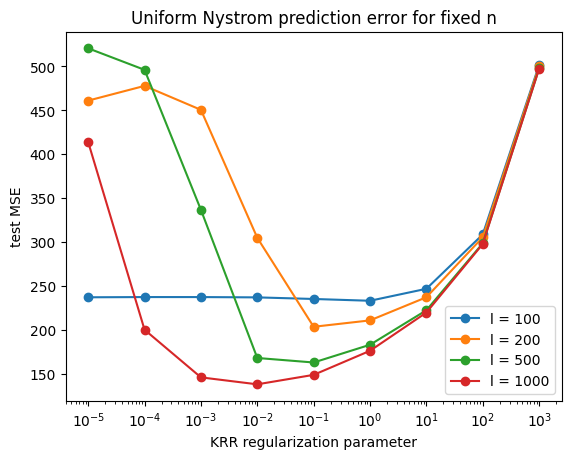

In [ ]:
plt.figure()

for l in uniform_l:
    sub = uniform_lambda_df[uniform_lambda_df["l"] == l]
    plt.semilogx(sub["lambda"], sub["test_mse"], marker="o", label="l = " + str(l))

plt.xlabel("KRR regularization parameter")
plt.ylabel("test MSE")
plt.title("Uniform Nystrom prediction error for fixed n")
plt.legend()
#plt.savefig("../Results/final_uniform_fixed_n_mse_vs_lambda.pdf") 
plt.show()